In [1]:
import torch

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
x = torch.linspace(-2, 2, 60).unsqueeze(1)

In [4]:
x

tensor([[-2.0000],
        [-1.9322],
        [-1.8644],
        [-1.7966],
        [-1.7288],
        [-1.6610],
        [-1.5932],
        [-1.5254],
        [-1.4576],
        [-1.3898],
        [-1.3220],
        [-1.2542],
        [-1.1864],
        [-1.1186],
        [-1.0508],
        [-0.9831],
        [-0.9153],
        [-0.8475],
        [-0.7797],
        [-0.7119],
        [-0.6441],
        [-0.5763],
        [-0.5085],
        [-0.4407],
        [-0.3729],
        [-0.3051],
        [-0.2373],
        [-0.1695],
        [-0.1017],
        [-0.0339],
        [ 0.0339],
        [ 0.1017],
        [ 0.1695],
        [ 0.2373],
        [ 0.3051],
        [ 0.3729],
        [ 0.4407],
        [ 0.5085],
        [ 0.5763],
        [ 0.6441],
        [ 0.7119],
        [ 0.7797],
        [ 0.8475],
        [ 0.9153],
        [ 0.9831],
        [ 1.0508],
        [ 1.1186],
        [ 1.1864],
        [ 1.2542],
        [ 1.3220],
        [ 1.3898],
        [ 1.4576],
        [ 1.

In [10]:
noise = 0.6 * torch.randn_like(x)
y = 3 * x + 2 + noise

In [6]:
import matplotlib.pyplot as plt

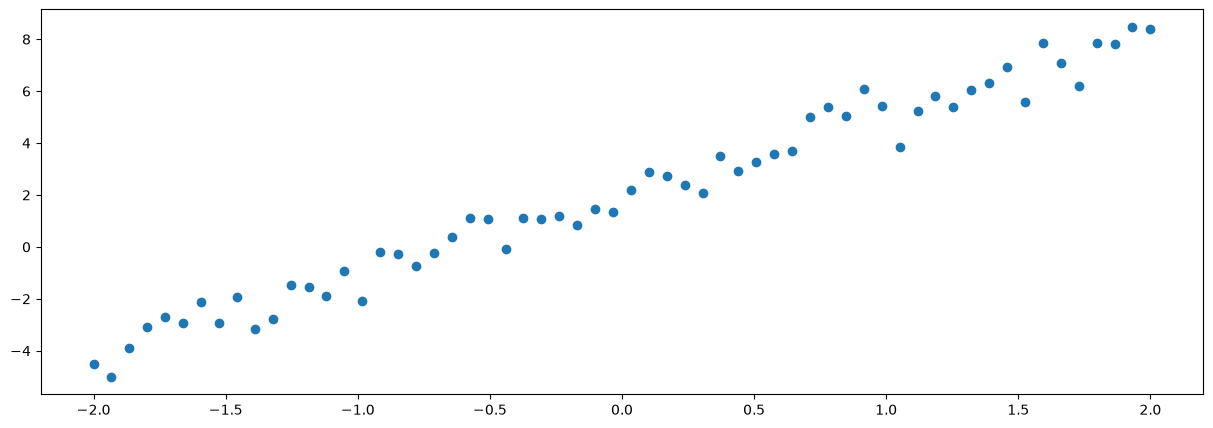

In [11]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)

In [12]:
import torch.nn as nn

In [13]:
model =nn.Linear(1, 1)

In [29]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
epochs = 100
losses = []
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y, y_pred)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0:
        print(f"Epoch : {epoch}/{epochs}, loss = {loss.item()}")

Epoch : 0/100, loss = 96.1435317993164


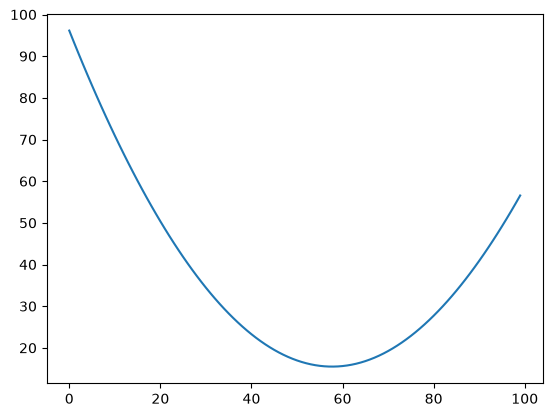

In [30]:
plt.plot(losses)

In [19]:
with torch.inference_mode():
    pred = model(x)
    

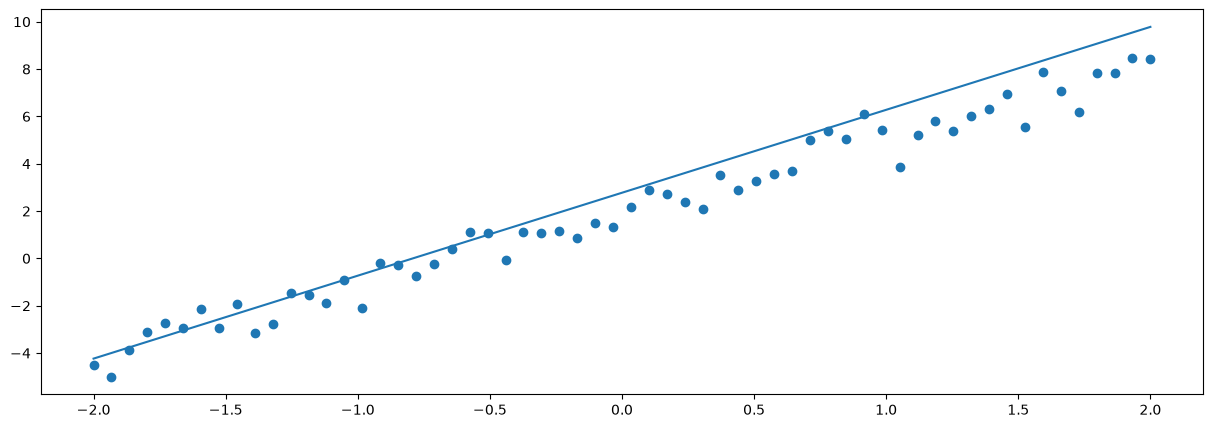

In [20]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)
plt.plot(x, pred)

In [21]:
from torcheval.metrics import R2Score

In [22]:
r2_score = R2Score()
r2_score.update(y, pred)
score = r2_score.compute()

In [23]:
print(score)

tensor(0.9309)
